Importing all required libraries

In [41]:
%pip install xgboost
%pip install lightgbm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 1.7 MB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 2.4 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 2.5 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Data Preprocessing 

In [42]:
raw_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\data\raw"
raw_file_path = os.path.join(raw_dir, "ai4i2020_messy.csv")

In [43]:
df=pd.read_csv(raw_file_path)

In [44]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551.0,42.8,0.0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3.0,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5.0,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433.0,39.5,7.0,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9.0,0,0,0,0,0,0


In [45]:
df.shape

(10150, 14)

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10150 entries, 0 to 10149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10150 non-null  int64  
 1   Product ID               10150 non-null  str    
 2   Type                     9850 non-null   str    
 3   Air temperature [K]      9851 non-null   float64
 4   Process temperature [K]  9850 non-null   float64
 5   Rotational speed [rpm]   9850 non-null   float64
 6   Torque [Nm]              9850 non-null   float64
 7   Tool wear [min]          9851 non-null   float64
 8   Machine failure          10150 non-null  int64  
 9   TWF                      10150 non-null  int64  
 10  HDF                      10150 non-null  int64  
 11  PWF                      10150 non-null  int64  
 12  OSF                      10150 non-null  int64  
 13  RNF                      10150 non-null  int64  
dtypes: float64(5), int64(7), str(2)
m

In [47]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10150.000000,9851.000000,9850.000000,9850.000000,9850.000000,9851.000000,10150.000000,10150.000000,10150.000000,10150.000000,10150.000000,10150.000000
mean,5003.092118,300.536504,310.007147,1556.271472,40.414904,138.144452,0.033793,0.004532,0.011527,0.009458,0.009754,0.001970
std,2885.816207,30.597722,1.481155,560.436920,21.837716,548.718492,0.180705,0.067171,0.106749,0.096797,0.098283,0.044348
min,1.000000,-50.000000,305.700000,-500.000000,-150.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2509.250000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5004.500000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,7498.750000,301.500000,311.100000,1612.000000,46.800000,163.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,10000.000000,999.900000,313.800000,15000.000000,500.000000,9999.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [48]:
#checking null values 
df.isna().sum()

UDI                          0
Product ID                   0
Type                       300
Air temperature [K]        299
Process temperature [K]    300
Rotational speed [rpm]     300
Torque [Nm]                300
Tool wear [min]            299
Machine failure              0
TWF                          0
HDF                          0
PWF                          0
OSF                          0
RNF                          0
dtype: int64

In [49]:
#checking duplicates
print("number of duplicate rows:",df.duplicated().sum())
# Check duplicate UDI records
print("\nDuplicate UDI Records:")
print(df["UDI"].duplicated().sum())

number of duplicate rows: 121

Duplicate UDI Records:
150


Expository Data Analytics

In [50]:
# Select numerical columns
num_cols = df.select_dtypes(include='number').columns

# Exclude identifier and binary columns
num_cols = [
    col for col in num_cols
    if col != 'UDI' and df[col].nunique(dropna=True) > 2
]

print("Numerical features selected for outlier analysis:")
print(num_cols)

Numerical features selected for outlier analysis:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


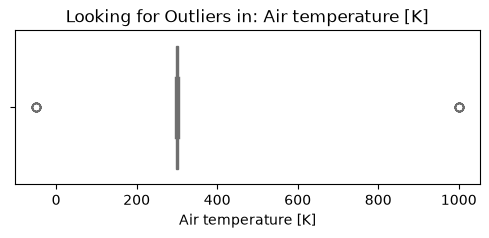

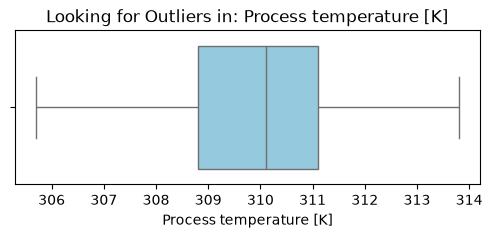

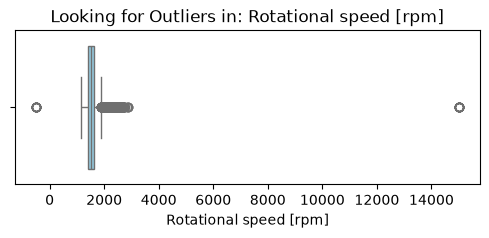

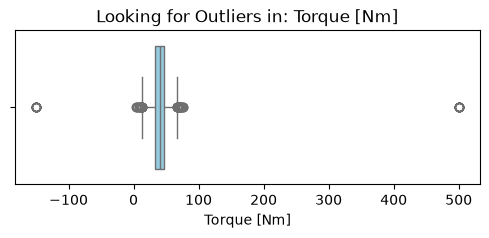

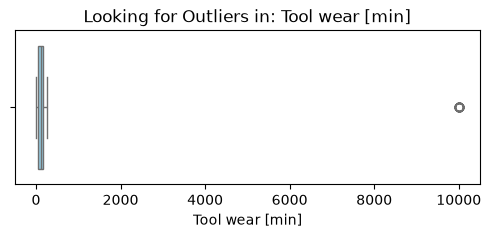

All boxplots saved successfully in: F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\figures


In [51]:
#find and making box plot for outlier of  numerical features
output_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\figures"
os.makedirs(output_dir, exist_ok=True)

for col in num_cols:
    plt.figure(figsize=(6, 2))
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Looking for Outliers in: {col}')

    safe_col_name = col.replace(" ", "_").replace("[", "").replace("]", "").replace("/", "_")
    file_path = os.path.join(output_dir, f"boxplot_{safe_col_name}.png")

    plt.savefig(file_path, bbox_inches='tight', dpi=300)
    plt.show()
    plt.close()
print(f"All boxplots saved successfully in: {output_dir}")

In [52]:
# Finding outliers in numerical features

for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    if len(outliers) > 0:
        print(f"{col}: Found {len(outliers)} outliers.")
    else:
        print(f"{col}: No outliers.")

Air temperature [K]: Found 30 outliers.
Process temperature [K]: No outliers.
Rotational speed [rpm]: Found 447 outliers.
Torque [Nm]: Found 99 outliers.
Tool wear [min]: Found 30 outliers.


In [53]:
#defining place where we save our figures
output_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\figures"
os.makedirs(output_dir, exist_ok=True)

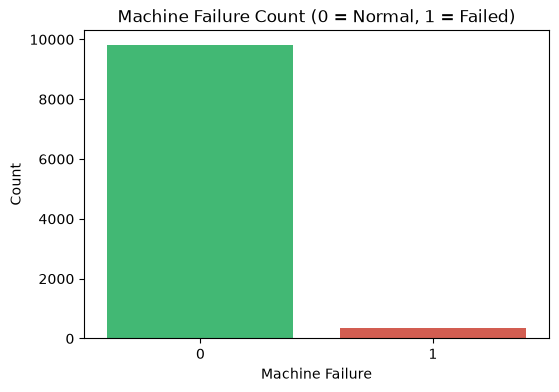

In [54]:
# target distribution plot
plt.figure(figsize=(6, 4))
sns.countplot(
    data=df,
    x='Machine failure',
    hue='Machine failure',
    palette=['#2ecc71', '#e74c3c'],
    legend=False,
)

plt.title('Machine Failure Count (0 = Normal, 1 = Failed)')
plt.xlabel('Machine Failure')
plt.ylabel('Count')

plt.savefig(
    os.path.join(output_dir, 'target_distribution.png'), bbox_inches='tight'
)
plt.show()
plt.close()

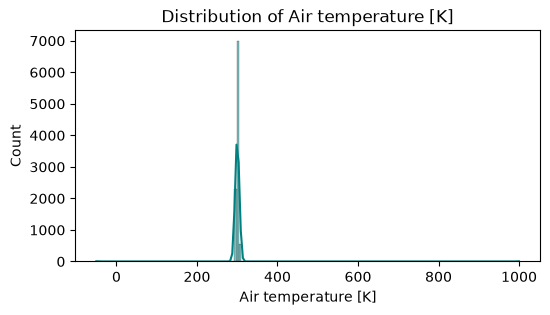

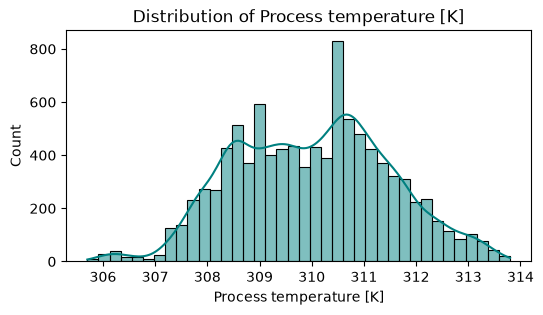

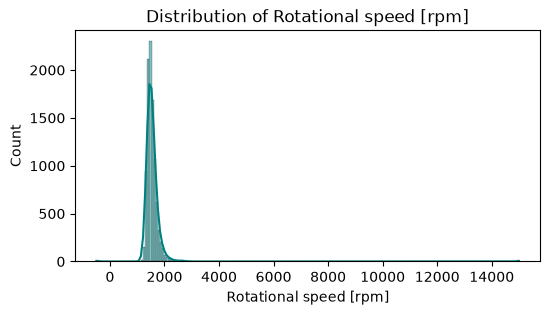

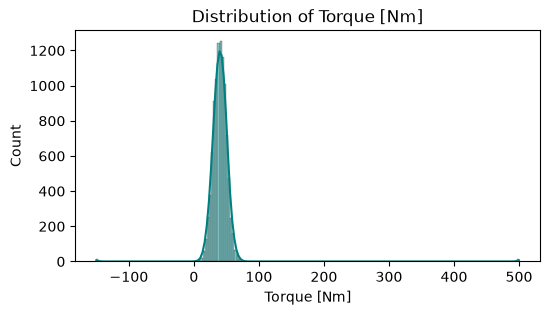

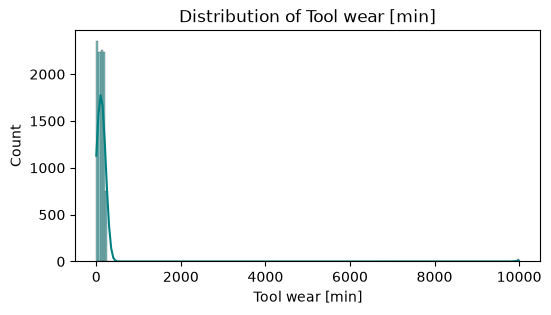

In [55]:
#Distribution Histograms (One Graph per Feature)
# List of main sensor columns
num_cols = [
    'Air temperature [K]', 
    'Process temperature [K]', 
    'Rotational speed [rpm]', 
    'Torque [Nm]', 
    'Tool wear [min]'
]

# Plot a simple histogram for each feature
for col in num_cols:
    plt.figure(figsize=(6, 3))
    sns.histplot(df[col], kde=True, color='teal')
    plt.title(f'Distribution of {col}')
    
    # Save image with safe filename
    clean_name = col.replace(" ", "_").replace("[", "").replace("]", "")
    plt.savefig(os.path.join(output_dir, f"hist_{clean_name}.png"), bbox_inches='tight')
    plt.show()
    plt.close()

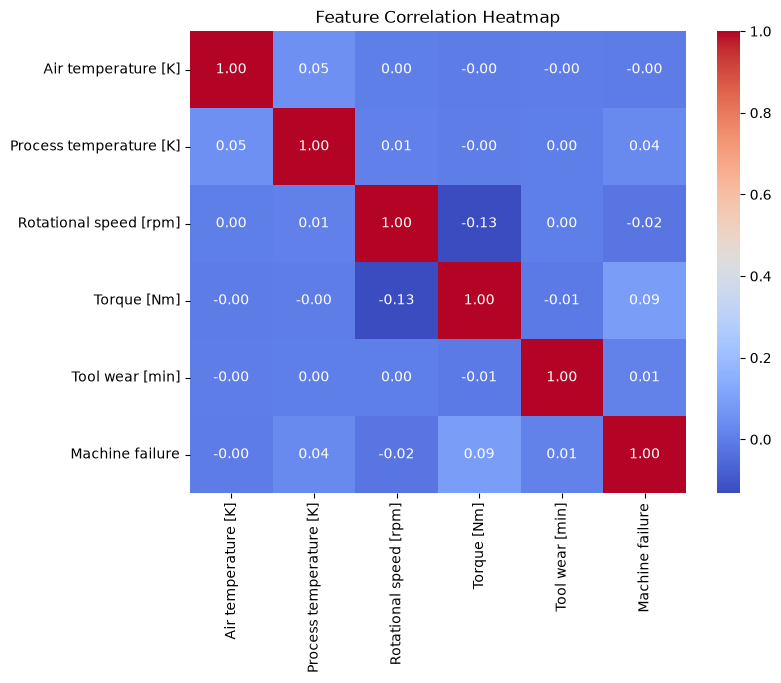

All graphs saved in: F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\figures


In [56]:
plt.figure(figsize=(8, 6))
fet_to_check=num_cols+['Machine failure']
sns.heatmap(df[fet_to_check].corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title('Feature Correlation Heatmap')
# Save and display image
plt.savefig(os.path.join(output_dir, "correlation_heatmap.png"), bbox_inches='tight')
plt.show()
plt.close()

print(f"All graphs saved in: {output_dir}")

Data cleaning 

In [57]:
#removing duplicates
df=df.drop_duplicates().reset_index(drop=True)


In [58]:
#checking duplicates
print("number of duplicate rows:",df.duplicated().sum())

number of duplicate rows: 0


In [59]:
# Merge remaining records with the same UDI
df = (
    df.groupby("UDI", sort=False)
      .first()
      .reset_index()
)

print("Rows after merging repeated UDI:", len(df))
print("Remaining duplicate UDI:", df["UDI"].duplicated().sum())

Rows after merging repeated UDI: 10000
Remaining duplicate UDI: 0


In [60]:
# Recover missing Type values using Product ID
missing_before = df['Type'].isnull().sum()

df.loc[df['Type'].isnull(), 'Type'] = (
    df.loc[df['Type'].isnull(), 'Product ID'].str[0]
)

missing_after = df['Type'].isnull().sum()

print("Missing Type values before recovery:", missing_before)
print("Missing Type values after recovery:", missing_after)

print("\nType distribution:")
print(df['Type'].value_counts(dropna=False))

# Drop non-predictive identifier columns
cols_to_drop = ['UDI', 'Product ID']
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

print("\nRemaining columns:")
print(df.columns.tolist())

Missing Type values before recovery: 293
Missing Type values after recovery: 0

Type distribution:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Remaining columns:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [61]:
# STEP 1: Label Consistency Audit

failure_modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

# Check whether at least one failure mode is active
df['Failure_Mode_Indicated'] = (
    df[failure_modes].sum(axis=1) > 0
).astype(int)

# Compare with Machine failure
print("Machine Failure Distribution:")
print(df['Machine failure'].value_counts())

print("\nFailure Mode Indicated Distribution:")
print(df['Failure_Mode_Indicated'].value_counts())

# Find inconsistent records
inconsistent_records = df[
    df['Machine failure'] != df['Failure_Mode_Indicated']
]

print("\nInconsistent Records:", len(inconsistent_records))

print("\nInconsistent Record Details:")
display(
    inconsistent_records[
        ['Machine failure'] + failure_modes +
        ['Failure_Mode_Indicated']
    ].head(10)
)

Machine Failure Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure Mode Indicated Distribution:
Failure_Mode_Indicated
0    9652
1     348
Name: count, dtype: int64

Inconsistent Records: 27

Inconsistent Record Details:


,Machine failure,TWF,HDF,PWF,OSF,RNF,Failure_Mode_Indicated
1221,0,0,0,0,0,1,1
1302,0,0,0,0,0,1,1
1437,1,0,0,0,0,0,0
1748,0,0,0,0,0,1,1
2072,0,0,0,0,0,1,1
2559,0,0,0,0,0,1,1
2749,1,0,0,0,0,0,0
3065,0,0,0,0,0,1,1
3452,0,0,0,0,0,1,1
4044,1,0,0,0,0,0,0


In [62]:
# STEP 2: Categorize inconsistent records

false_failure_modes = inconsistent_records[
    (inconsistent_records['Machine failure'] == 0) &
    (inconsistent_records['Failure_Mode_Indicated'] == 1)
]

missing_failure_modes = inconsistent_records[
    (inconsistent_records['Machine failure'] == 1) &
    (inconsistent_records['Failure_Mode_Indicated'] == 0)
]

print("Failure modes present but Machine failure = 0:",
      len(false_failure_modes))

print("Machine failure = 1 but no failure mode indicated:",
      len(missing_failure_modes))

Failure modes present but Machine failure = 0: 18
Machine failure = 1 but no failure mode indicated: 9


In [63]:
# Preserve inconsistent records for KBS analysis

inconsistent_records.to_csv(
    "inconsistent_label_records.csv",
    index=True
)

print("Inconsistent records saved successfully.")

Inconsistent records saved successfully.


In [64]:
# Remove audit helper column before ML split
df = df.drop(columns=['Failure_Mode_Indicated'])

print("Failure_Mode_Indicated removed:",
      'Failure_Mode_Indicated' not in df.columns)

Failure_Mode_Indicated removed: True


In [66]:
import os

#saving clean data set to desired location
processed_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\data\processed"
file_name = "ai4i2020_cleaned.csv"
output_path = os.path.join(processed_dir, file_name)

os.makedirs(processed_dir, exist_ok=True)

# 2. Save the DataFrame to CSV 
df.to_csv(output_path, index=False)

print(f"Dataset successfully saved to:\n{output_path}")



Dataset successfully saved to:
F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\data\processed\ai4i2020_cleaned.csv


Train-test split

In [67]:
from sklearn.model_selection import train_test_split

# Separate input features and target variable
X = df.drop(columns=['Machine failure'])
y = df['Machine failure']

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Preserve failure-mode labels for KBS
failure_modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

y_train_modes = df.loc[X_train.index, failure_modes].copy()
y_test_modes = df.loc[X_test.index, failure_modes].copy()

# Remove failure-mode labels from ML features only
X_train = X_train.drop(columns=failure_modes)
X_test = X_test.drop(columns=failure_modes)

# Check dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

# Verify that leakage columns are removed
print("\nFailure_Mode_Indicated in X_train:",
      'Failure_Mode_Indicated' in X_train.columns)

print("\nFailure mode flags in X_train:")
print([col for col in failure_modes if col in X_train.columns])

# Verify preserved KBS labels
print("\nTraining KBS labels:", y_train_modes.shape)
print("Testing KBS labels:", y_test_modes.shape)

Training features: (8000, 6)
Testing features: (2000, 6)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64

Failure_Mode_Indicated in X_train: False

Failure mode flags in X_train:
[]

Training KBS labels: (8000, 5)
Testing KBS labels: (2000, 5)


In [68]:
# 1. Define target directory
processed_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\tables"
os.makedirs(processed_dir, exist_ok=True)

# Export train and test sets to CSV 
X_train.to_csv(os.path.join(processed_dir, "X_train.csv"), index=False)
y_train.to_csv(os.path.join(processed_dir, "y_train.csv"), index=False)
X_test.to_csv(os.path.join(processed_dir, "X_test.csv"), index=False)
y_test.to_csv(os.path.join(processed_dir, "y_test.csv"), index=False)

print("Train and test splits saved successfully!")
print(f"Saved directory: {processed_dir}\n")

# verification check
files = ["X_train.csv", "y_train.csv", "X_test.csv", "y_test.csv"]
for file in files:
    file_path = os.path.join(processed_dir, file)
    size_kb = os.path.getsize(file_path) / 1024
    print(f" - {file:<12}: {size_kb:.2f} KB")

Train and test splits saved successfully!
Saved directory: F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\tables

 - X_train.csv : 248.27 KB
 - y_train.csv : 23.45 KB
 - X_test.csv  : 62.23 KB
 - y_test.csv  : 5.88 KB


Missing value handling

In [69]:
# Check missing values before imputation
print("Missing values in training data:")
print(X_train.isnull().sum())

print("\nMissing values in testing data:")
print(X_test.isnull().sum())

# Numerical features: Fill missing values with training median
sensor_cols = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

for col in sensor_cols:
    if col in X_train.columns:
        col_median = X_train[col].median()

        X_train[col] = X_train[col].fillna(col_median)
        X_test[col] = X_test[col].fillna(col_median)

# Verify missing values
print("\nRemaining missing values in training data:",
      X_train.isnull().sum().sum())

print("Remaining missing values in testing data:",
      X_test.isnull().sum().sum())

Missing values in training data:
Type                         0
Air temperature [K]        243
Process temperature [K]    241
Rotational speed [rpm]     238
Torque [Nm]                232
Tool wear [min]            236
dtype: int64

Missing values in testing data:
Type                        0
Air temperature [K]        52
Process temperature [K]    56
Rotational speed [rpm]     58
Torque [Nm]                67
Tool wear [min]            53
dtype: int64

Remaining missing values in training data: 0
Remaining missing values in testing data: 0


Invalid values and IQR capping

In [70]:

import numpy as np

# Define physically plausible sensor ranges
valid_ranges = {
    'Air temperature [K]':     (273, 350),
    'Process temperature [K]': (273, 350),
    'Rotational speed [rpm]':  (0, 4000),
    'Torque [Nm]':             (0, 100),
    'Tool wear [min]':         (0, 300)
}

# Rotational speed and Torque must be greater than zero
exclusive_lower = [
    'Rotational speed [rpm]',
    'Torque [Nm]'
]

# STEP 1: Identify and replace invalid readings with NaN
print("Invalid values identified (Train / Test):")

for col, (lower, upper) in valid_ranges.items():

    if col in exclusive_lower:
        train_invalid = (
            (X_train[col] <= lower) | (X_train[col] > upper)
        )
        test_invalid = (
            (X_test[col] <= lower) | (X_test[col] > upper)
        )
    else:
        train_invalid = (
            (X_train[col] < lower) | (X_train[col] > upper)
        )
        test_invalid = (
            (X_test[col] < lower) | (X_test[col] > upper)
        )

    train_count = train_invalid.sum()
    test_count = test_invalid.sum()

    X_train.loc[train_invalid, col] = np.nan
    X_test.loc[test_invalid, col] = np.nan

    print(f"{col}: {train_count} / {test_count}")

# STEP 2: Impute missing and invalid values using training median
for col in valid_ranges:

    median_value = X_train[col].median()

    X_train[col] = X_train[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

# STEP 3: Verify remaining missing values
print("\nRemaining missing values:")
print("Training:", X_train.isnull().sum().sum())
print("Testing:", X_test.isnull().sum().sum())

# STEP 4: Check final sensor value ranges
print("\nFinal sensor ranges in training data:")
print(X_train[list(valid_ranges)].agg(['min', 'max']).round(2))

print("\nFinal sensor ranges in testing data:")
print(X_test[list(valid_ranges)].agg(['min', 'max']).round(2))

print("\nDomain-based outlier handling completed.")


Invalid values identified (Train / Test):
Air temperature [K]: 24 / 6
Process temperature [K]: 0 / 0
Rotational speed [rpm]: 23 / 7
Torque [Nm]: 24 / 5
Tool wear [min]: 24 / 6

Remaining missing values:
Training: 0
Testing: 0

Final sensor ranges in training data:
     Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
min                295.3                    305.7                  1168.0   
max                304.5                    313.8                  2886.0   

     Torque [Nm]  Tool wear [min]  
min          3.8              0.0  
max         76.6            253.0  

Final sensor ranges in testing data:
     Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
min                295.3                    305.8                  1202.0   
max                304.4                    313.6                  2825.0   

     Torque [Nm]  Tool wear [min]  
min          5.8              0.0  
max         72.0            246.0  

Domain-based out

In [71]:
# Saving processed training and testing datasets
processed_dir =  r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\tables"

os.makedirs(processed_dir, exist_ok=True)

X_train.to_csv(os.path.join(processed_dir, "X_train_cleaned.csv"), index=False)
X_test.to_csv(os.path.join(processed_dir, "X_test_cleaned.csv"), index=False)

y_train.to_csv(os.path.join(processed_dir, "y_train.csv"), index=False)
y_test.to_csv(os.path.join(processed_dir, "y_test.csv"), index=False)

print("Processed training and testing datasets saved successfully.")

Processed training and testing datasets saved successfully.


Feature Engineering

In [72]:
# STEP 1: Create physics-based features

def create_features(data):

    data = data.copy()

    # 1. Temperature Difference
    data['Temp_diff'] = (
        data['Process temperature [K]'] -
        data['Air temperature [K]']
    )

    # 2. Mechanical Power (Watts)
    data['Power'] = (
        data['Torque [Nm]'] *
        (data['Rotational speed [rpm]'] * (2 * np.pi / 60))
    )

    # 3. Overstrain Index
    data['Overstrain_Index'] = (
        data['Tool wear [min]'] *
        data['Torque [Nm]']
    )

    # 4. Torque-Speed Ratio
    data['Torque_Speed_Ratio'] = (
        data['Torque [Nm]'] /
        (data['Rotational speed [rpm]'] + 1e-5)
    )

    return data


X_train = create_features(X_train)
X_test = create_features(X_test)


# STEP 2: One-Hot Encoding of Product Type
X_train = pd.get_dummies(
    X_train, columns=['Type'], drop_first=True, dtype=int
)

X_test = pd.get_dummies(
    X_test, columns=['Type'], drop_first=True, dtype=int
)

# Ensure both datasets have identical columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)


# STEP 3: Verify engineered features
print("Training dataset shape:", X_train.shape)
print("Testing dataset shape:", X_test.shape)

print("\nEngineered features:")
print([
    'Temp_diff',
    'Power',
    'Overstrain_Index',
    'Torque_Speed_Ratio'
])

print("\nFinal training columns:")
print(X_train.columns.tolist())

print("\nTraining data preview:")
display(X_train.head())

Training dataset shape: (8000, 11)
Testing dataset shape: (2000, 11)

Engineered features:
['Temp_diff', 'Power', 'Overstrain_Index', 'Torque_Speed_Ratio']

Final training columns:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temp_diff', 'Power', 'Overstrain_Index', 'Torque_Speed_Ratio', 'Type_L', 'Type_M']

Training data preview:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temp_diff,Power,Overstrain_Index,Torque_Speed_Ratio,Type_L,Type_M
4058,302.0,310.9,1456.0,47.2,54.0,8.9,7196.676675,2548.8,0.032418,0,1
1221,297.0,308.3,1399.0,46.4,132.0,11.3,6797.736296,6124.8,0.033167,0,1
6895,301.0,311.6,1357.0,45.6,137.0,10.6,6479.974671,6247.2,0.033604,0,1
9863,298.9,309.8,1411.0,56.3,84.0,10.9,8318.864043,4729.2,0.039901,1,0
8711,297.1,308.5,1733.0,28.7,50.0,11.4,5208.456932,1435.0,0.016561,1,0


In [73]:
# Save engineered training and testing datasets
processed_dir =  r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\data\processed"

os.makedirs(processed_dir, exist_ok=True)

X_train.to_csv(
    os.path.join(processed_dir, "X_train_engineered.csv"),
    index=False
)

X_test.to_csv(
    os.path.join(processed_dir, "X_test_engineered.csv"),
    index=False
)

y_train.to_csv(
    os.path.join(processed_dir, "y_train.csv"),
    index=False
)

y_test.to_csv(
    os.path.join(processed_dir, "y_test.csv"),
    index=False
)

print("All engineered datasets saved successfully!")

All engineered datasets saved successfully!


In [74]:
# Check target distribution in training and testing data

print("TRAINING DATA DISTRIBUTION")
print(y_train.value_counts())
print("\nTraining percentage:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTESTING DATA DISTRIBUTION")
print(y_test.value_counts())
print("\nTesting percentage:")
print((y_test.value_counts(normalize=True) * 100).round(2))

TRAINING DATA DISTRIBUTION
Machine failure
0    7729
1     271
Name: count, dtype: int64

Training percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

TESTING DATA DISTRIBUTION
Machine failure
0    1932
1      68
Name: count, dtype: int64

Testing percentage:
Machine failure
0    96.6
1     3.4
Name: proportion, dtype: float64


Feature Scaling Logistic Regression

In [75]:
from sklearn.preprocessing import StandardScaler

# Scale features for Logistic Regression only
binary_cols = ['Type_L', 'Type_M']
continuous_cols = [
    col for col in X_train.columns
    if col not in binary_cols
]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[continuous_cols] = scaler.fit_transform(
    X_train[continuous_cols]
)

X_test_scaled[continuous_cols] = scaler.transform(
    X_test[continuous_cols]
)

print("Feature scaling completed for Logistic Regression.")
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Feature scaling completed for Logistic Regression.
Training shape: (8000, 11)
Testing shape: (2000, 11)


Model_training 


In [76]:
from sklearn.linear_model import LogisticRegression

model_lg = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

model_lg.fit(X_train_scaled, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [77]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    class_weight='balanced',
    random_state=42,
    n_estimators=200,
    max_depth=10,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [78]:
from xgboost import XGBClassifier

# Calculate class imbalance ratio
scale_pos_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

# Create safe feature names for XGBoost
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

X_train_xgb.columns = [
    col.replace('[', '').replace(']', '').replace('<', '')
    .replace(' ', '_')
    for col in X_train_xgb.columns
]

X_test_xgb.columns = X_train_xgb.columns

# Create XGBoost model
model_xg = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss'
)

# Train XGBoost
model_xg.fit(X_train_xgb, y_train)

print("XGBoost training completed.")
print("Scale positive weight:", round(scale_pos_weight, 2))

XGBoost training completed.
Scale positive weight: 28.52


In [79]:
from lightgbm import LGBMClassifier
import re

# Create separate copies for LightGBM
X_train_lgbm = X_train.copy()
X_test_lgbm = X_test.copy()

# Clean feature names
def clean_col(col):
    return re.sub(r'[^A-Za-z0-9_]', '_', col)

X_train_lgbm.columns = [
    clean_col(col) for col in X_train_lgbm.columns
]

X_test_lgbm.columns = X_train_lgbm.columns

# Calculate class imbalance ratio
scale_pos_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

# Create LightGBM model
lgbm_model = LGBMClassifier(
    n_estimators=200,
    max_depth=-1,
    learning_rate=0.05,
    num_leaves=31,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    verbosity=-1
)

# Train LightGBM
lgbm_model.fit(X_train_lgbm, y_train)

print("LightGBM training completed.")
print("Scale positive weight:", round(scale_pos_weight, 2))

LightGBM training completed.
Scale positive weight: 28.52


prediction and evaluation

In [80]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Logistic Regression
y_pred_lg = model_lg.predict(X_test_scaled)
y_proba_lg = model_lg.predict_proba(X_test_scaled)[:, 1]

print("LOGISTIC REGRESSION")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lg))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lg))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_lg))


# Random Forest
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("\nRANDOM FOREST")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))


# XGBoost
y_pred_xgb = model_xg.predict(X_test_xgb)
y_proba_xgb = model_xg.predict_proba(X_test_xgb)[:, 1]

print("\nXGBOOST")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_xgb))

y_pred_lgbm = lgbm_model.predict(X_test_lgbm)
y_prob_lgbm = lgbm_model.predict_proba(X_test_lgbm)[:, 1]

print("LIGHTGBM EVALUATION")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lgbm))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lgbm,
    target_names=['Normal', 'Failure'],
    zero_division=0
))

print("\nROC-AUC:", roc_auc_score(y_test, y_prob_lgbm))

LOGISTIC REGRESSION
Confusion Matrix:
[[1645  287]
 [  10   58]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.85      0.92      1932
           1       0.17      0.85      0.28        68

    accuracy                           0.85      2000
   macro avg       0.58      0.85      0.60      2000
weighted avg       0.97      0.85      0.90      2000

ROC-AUC: 0.9259606016319571

RANDOM FOREST
Confusion Matrix:
[[1901   31]
 [  18   50]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1932
           1       0.62      0.74      0.67        68

    accuracy                           0.98      2000
   macro avg       0.80      0.86      0.83      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC: 0.9721334185848253

XGBOOST
Confusion Matrix:
[[1921   11]
 [  15   53]]

Classification Report:
              precision    recall  f1-s

In [81]:
print("ROC-AUC Comparison")

print("Logistic Regression:", roc_auc_score(y_test, y_proba_lg))
print("Random Forest:", roc_auc_score(y_test, y_prob_rf))
print("XGBoost:", roc_auc_score(y_test, y_proba_xgb))
print("LightGBM:", roc_auc_score(y_test, y_prob_lgbm))

ROC-AUC Comparison
Logistic Regression: 0.9259606016319571
Random Forest: 0.9721334185848253
XGBoost: 0.9489099987821216
LightGBM: 0.9471288515406161


In [82]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

comparison_data = []

models_results = {
    "Logistic Regression": (y_pred_lg, y_proba_lg),
    "Random Forest": (y_pred_rf, y_prob_rf),
    "XGBoost": (y_pred_xgb, y_proba_xgb),
    "LightGBM": (y_pred_lgbm, y_prob_lgbm)
}

for name, (pred, prob) in models_results.items():
    cm = confusion_matrix(y_test, pred)

    comparison_data.append({
        "Model": name,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "False Positives": cm[0][1],
        "False Negatives": cm[1][0]
    })

comparison_df = pd.DataFrame(comparison_data)

table_dir =  r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\tables"
os.makedirs(table_dir, exist_ok=True)

csv_save_path = os.path.join(table_dir, "model_comparison.csv")
comparison_df.to_csv(csv_save_path, index=False)

display(comparison_df.round(4))

print("Comparison table saved at:", csv_save_path)

,Model,Precision,Recall,F1-Score,ROC-AUC,False Positives,False Negatives
0,Logistic Regression,0.1681,0.8529,0.2809,0.9260,287,10
1,Random Forest,0.6173,0.7353,0.6711,0.9721,31,18
2,XGBoost,0.8281,0.7794,0.8030,0.9489,11,15
3,LightGBM,0.8000,0.7647,0.7820,0.9471,13,16


Comparison table saved at: F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\tables\model_comparison.csv


In [83]:
#this XGBoost model can perform well but we can increase acuracy even more using hyper parameter tunning

Hyper Parameter Tunning:

In [84]:
import re

def clean_col(col):
    return re.sub(r'[\[\]<>]', '', col)

X_train_xgb = X_train_xgb.copy()
X_test_xgb = X_test_xgb.copy()

X_train_xgb.columns = [clean_col(c) for c in X_train_xgb.columns]
X_test_xgb.columns = [clean_col(c) for c in X_test_xgb.columns]

print("XGBoost feature names:")
print(X_train_xgb.columns.tolist())

XGBoost feature names:
['Air_temperature_K', 'Process_temperature_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Temp_diff', 'Power', 'Overstrain_Index', 'Torque_Speed_Ratio', 'Type_L', 'Type_M']


In [85]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from xgboost import XGBClassifier

# Parameter grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'scale_pos_weight': [10, 15, 20, 28.52]
}

# Base XGBoost model
base_xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    n_jobs=1
)

# 5-Fold Stratified Cross Validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Randomized Search
search = RandomizedSearchCV(
    estimator=base_xgb,
    param_distributions=param_grid,
    n_iter=15,
    scoring='f1',
    cv=skf,
    random_state=42,
    n_jobs=-1
)

print("Running Randomized Search CV...")

search.fit(X_train_xgb, y_train)

print("\nBest Parameters:")
print(search.best_params_)

print("\nBest F1 Score (CV):")
print(search.best_score_)

# Best tuned model
best_xgb = search.best_estimator_

Running Randomized Search CV...

Best Parameters:
{'subsample': 1.0, 'scale_pos_weight': 20, 'n_estimators': 300, 'max_depth': 9, 'learning_rate': 0.05, 'colsample_bytree': 0.8}

Best F1 Score (CV):
0.8339204744983653


In [86]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Predictions
y_pred_best = best_xgb.predict(X_test_xgb)
y_proba_best = best_xgb.predict_proba(X_test_xgb)[:, 1]

print("TUNED XGBOOST EVALUATION")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_best,
    target_names=['Normal', 'Failure'],
    zero_division=0
))

print("\nROC-AUC:", roc_auc_score(y_test, y_proba_best))

TUNED XGBOOST EVALUATION

Confusion Matrix:
[[1923    9]
 [  14   54]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99      1932
     Failure       0.86      0.79      0.82        68

    accuracy                           0.99      2000
   macro avg       0.92      0.89      0.91      2000
weighted avg       0.99      0.99      0.99      2000


ROC-AUC: 0.9652676287906466


In [87]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

import pandas as pd
import os

all_results = {
    "Logistic Regression": (y_pred_lg, y_proba_lg),
    "Random Forest": (y_pred_rf, y_prob_rf),
    "XGBoost (Baseline)": (y_pred_xgb, y_proba_xgb),
    "XGBoost (Tuned)": (y_pred_best, y_proba_best),
    "LightGBM": (y_pred_lgbm, y_prob_lgbm)
}

final_comparison = []

for name, (pred, prob) in all_results.items():

    cm = confusion_matrix(y_test, pred)

    final_comparison.append({
        "Model": name,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob),
        "False Positives": cm[0][1],
        "False Negatives": cm[1][0]
    })

df_comparison = pd.DataFrame(final_comparison)

table_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\tables"
os.makedirs(table_dir, exist_ok=True)

save_path = os.path.join(
    table_dir,
    "final_model_comparison.csv"
)

df_comparison.to_csv(save_path, index=False)

print("Final Model Comparison:")
display(df_comparison.round(4))

print("Comparison table saved:", save_path)

Final Model Comparison:


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,False Positives,False Negatives
0,Logistic Regression,0.1681,0.8529,0.2809,0.9260,0.3624,287,10
1,Random Forest,0.6173,0.7353,0.6711,0.9721,0.7730,31,18
2,XGBoost (Baseline),0.8281,0.7794,0.8030,0.9489,0.8297,11,15
3,XGBoost (Tuned),0.8571,0.7941,0.8244,0.9653,0.8392,9,14
4,LightGBM,0.8000,0.7647,0.7820,0.9471,0.8318,13,16


Comparison table saved: F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\tables\final_model_comparison.csv


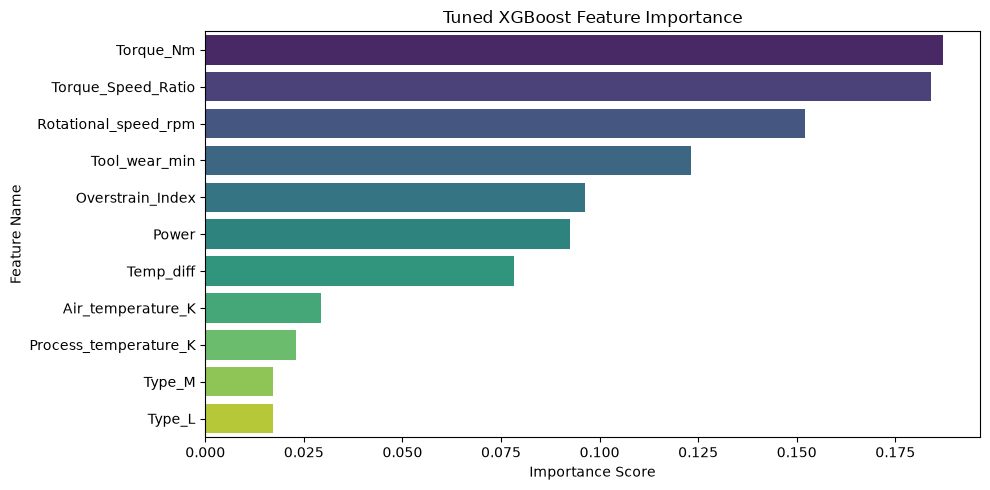

Feature importance chart saved: F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\tables\figures\xgb_tuned_feature_importance.png


,Feature,Importance
0,Torque_Nm,0.187123
1,Torque_Speed_Ratio,0.184015
2,Rotational_speed_rpm,0.152198
3,Tool_wear_min,0.123098
4,Overstrain_Index,0.096234
5,Power,0.092585
6,Temp_diff,0.078221
7,Air_temperature_K,0.029313
8,Process_temperature_K,0.022937
9,Type_M,0.017175


In [88]:
import matplotlib.pyplot as plt
import seaborn as sns

importances = best_xgb.feature_importances_
feature_names = X_train_xgb.columns

importance_df = (
    pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    })
    .sort_values(by='Importance', ascending=False)
    .reset_index(drop=True)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature',
    hue='Feature',
    legend=False,
    palette='viridis'
)

plt.title('Tuned XGBoost Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Feature Name')
plt.tight_layout()

fig_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\docs\tables\figures"
os.makedirs(fig_dir, exist_ok=True)

fig_path = os.path.join(fig_dir, 'xgb_tuned_feature_importance.png')

plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print("Feature importance chart saved:", fig_path)

display(importance_df)

saving model artifacts


In [89]:
import joblib

models_dir = r"F:\projects and codes\KBS_CCP_Project\kbs-industrial-fault-diagnosis\models"
os.makedirs(models_dir, exist_ok=True)

# Save tuned XGBoost model
joblib.dump(
    best_xgb,
    os.path.join(models_dir, "best_xgb_tuned.joblib")
)

# Save feature names used by XGBoost
joblib.dump(
    list(X_train_xgb.columns),
    os.path.join(models_dir, "feature_names.joblib")
)

# Save Logistic Regression scaler separately
joblib.dump(
    scaler,
    os.path.join(models_dir, "scaler.joblib")
)

print("All model artifacts saved successfully.")

All model artifacts saved successfully.
